In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")



Libraries imported successfully!


In [3]:
import pandas as pd

df = pd.read_excel('/content/CSV UTF-8.xlsx')

print(df.head())

   CustomerId  CreditScore Geography  Gender  Age  Tenure  Balance  \
0        1001          610     spain    male   49       9    37003   
1        1002          764   germany    male   25       0    85449   
2        1003          634   germany    male   49       4   138375   
3        1004          663   germany  female   49       8    14991   
4        1005          815    france  female   35       6    64489   

   NumOfProducts  HasCrCard  IsActiveMember  Estimated Salary  Exited  
0              3          0               1            188598       0  
1              1          1               1             21530       1  
2              4          0               0             80893       0  
3              4          0               0             32801       1  
4              2          0               0            168847       0  


In [4]:
print(df.columns)

Index(['CustomerId', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'Estimated Salary', 'Exited'],
      dtype='object')


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (312, 12)


In [6]:
print(df.isnull().sum())

CustomerId          0
CreditScore         0
Geography           0
Gender              0
Age                 0
Tenure              0
Balance             0
NumOfProducts       0
HasCrCard           0
IsActiveMember      0
Estimated Salary    0
Exited              0
dtype: int64


In [7]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerId        312 non-null    int64 
 1   CreditScore       312 non-null    int64 
 2   Geography         312 non-null    object
 3   Gender            312 non-null    object
 4   Age               312 non-null    int64 
 5   Tenure            312 non-null    int64 
 6   Balance           312 non-null    int64 
 7   NumOfProducts     312 non-null    int64 
 8   HasCrCard         312 non-null    int64 
 9   IsActiveMember    312 non-null    int64 
 10  Estimated Salary  312 non-null    int64 
 11  Exited            312 non-null    int64 
dtypes: int64(10), object(2)
memory usage: 29.4+ KB


In [9]:
df.describe()

,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,Estimated Salary,Exited
count,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000
mean,1156.500000,677.769231,38.282051,4.967949,97397.663462,2.387821,0.464744,0.490385,111687.657051,0.538462
std,90.210864,103.076430,12.481392,3.101540,56491.271239,1.137032,0.499557,0.500711,57145.478560,0.499319
min,1001.000000,503.000000,18.000000,0.000000,1017.000000,1.000000,0.000000,0.000000,10279.000000,0.000000
25%,1078.750000,581.750000,27.000000,2.000000,50874.250000,1.000000,0.000000,0.000000,63524.500000,0.000000
50%,1156.500000,673.000000,39.000000,5.000000,91372.000000,2.000000,0.000000,0.000000,117309.500000,1.000000
75%,1234.250000,767.500000,49.000000,8.000000,149314.500000,3.000000,1.000000,1.000000,159599.750000,1.000000
max,1312.000000,849.000000,60.000000,10.000000,199740.000000,4.000000,1.000000,1.000000,199835.000000,1.000000


In [12]:
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'],
             errors='ignore')

In [13]:
print(df.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Estimated Salary', 'Exited']


In [14]:
df = pd.get_dummies(df, drop_first=True)

In [15]:
print(df.head())
print(df.shape)

   CreditScore  Age  Tenure  Balance  NumOfProducts  HasCrCard  \
0          610   49       9    37003              3          0   
1          764   25       0    85449              1          1   
2          634   49       4   138375              4          0   
3          663   49       8    14991              4          0   
4          815   35       6    64489              2          0   

   IsActiveMember  Estimated Salary  Exited  Geography_germany  \
0               1            188598       0              False   
1               1             21530       1               True   
2               0             80893       0               True   
3               0             32801       1               True   
4               0            168847       0              False   

   Geography_spain  Gender_male  
0             True         True  
1            False         True  
2            False         True  
3            False        False  
4            False        False  
(3

In [16]:
X = df.drop('Exited', axis=1)
y = df['Exited']

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)

(249, 11)
(63, 11)


In [18]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [19]:
y_pred = model.predict(X_test)

print(y_pred)

[0 1 0 1 0 1 1 1 0 0 0 1 1 0 0 1 0 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0
 1 1 1 1 1 1 0 1 0 1 0 0 1 1 0 1 1 1 1 1 1 1 0 0 1 0]


In [20]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 57.14285714285714 %


In [21]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.55      0.41      0.47        29
           1       0.59      0.71      0.64        34

    accuracy                           0.57        63
   macro avg       0.57      0.56      0.56        63
weighted avg       0.57      0.57      0.56        63



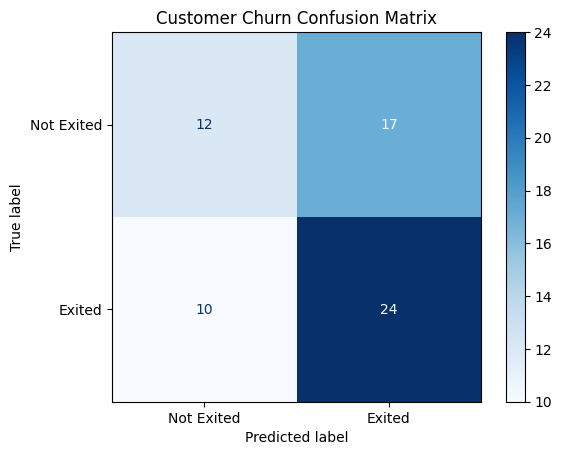

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Exited', 'Exited']
)

disp.plot(cmap='Blues')
plt.title('Customer Churn Confusion Matrix')
plt.show()

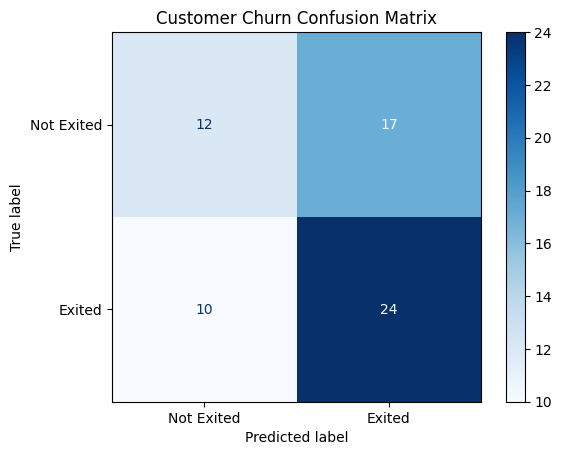

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Exited', 'Exited']
)

disp.plot(cmap='Blues')
plt.title('Customer Churn Confusion Matrix')
plt.show()

Balance              0.185478
Estimated Salary     0.185086
CreditScore          0.169688
Age                  0.167504
Tenure               0.107001
NumOfProducts        0.062715
Geography_germany    0.026230
IsActiveMember       0.025798
HasCrCard            0.024085
Gender_male          0.024053
Geography_spain      0.022362
dtype: float64


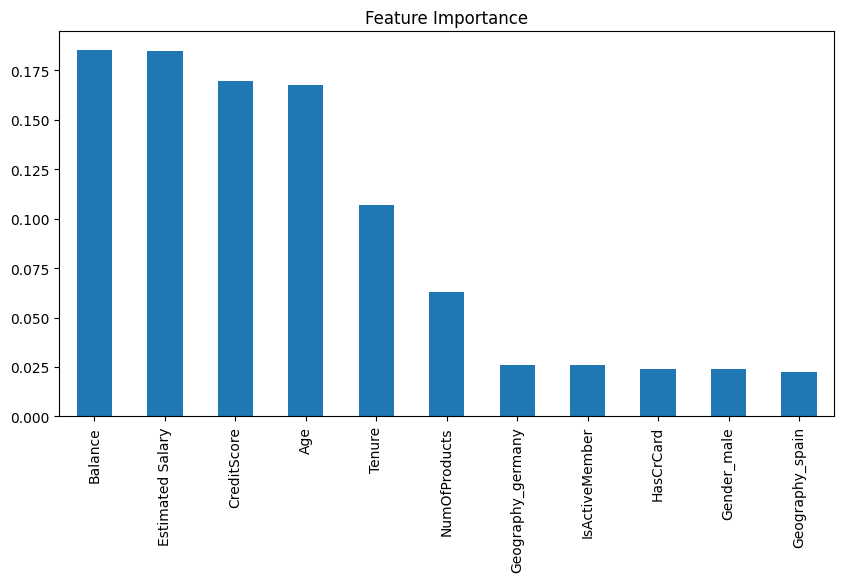

In [24]:
import pandas as pd

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

importance.plot(kind='bar', figsize=(10,5))
plt.title('Feature Importance')
plt.show()

In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.55      0.41      0.47        29
           1       0.59      0.71      0.64        34

    accuracy                           0.57        63
   macro avg       0.57      0.56      0.56        63
weighted avg       0.57      0.57      0.56        63



In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

model2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    class_weight='balanced',
    random_state=42
)

model2.fit(X_train, y_train)

y_pred2 = model2.predict(X_test)

print("New Accuracy:",
      accuracy_score(y_test, y_pred2) * 100)

New Accuracy: 58.730158730158735


In [27]:
print("Old Model Accuracy:",
      accuracy_score(y_test, y_pred) * 100)

print("New Model Accuracy:",
      accuracy_score(y_test, y_pred2) * 100)

Old Model Accuracy: 57.14285714285714
New Model Accuracy: 58.730158730158735


In [28]:
from sklearn.metrics import classification_report

print("NEW MODEL REPORT")
print(classification_report(y_test, y_pred2))

NEW MODEL REPORT
              precision    recall  f1-score   support

           0       0.55      0.55      0.55        29
           1       0.62      0.62      0.62        34

    accuracy                           0.59        63
   macro avg       0.58      0.58      0.58        63
weighted avg       0.59      0.59      0.59        63



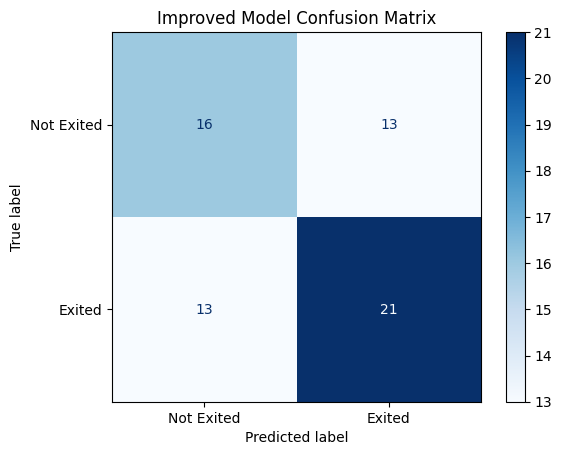

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred2)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Exited', 'Exited']
).plot(cmap='Blues')

plt.title("Improved Model Confusion Matrix")
plt.show()

In [30]:
import joblib

joblib.dump(model2, 'bank_churn_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [31]:
from google.colab import files

files.download('bank_churn_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from google.colab import files

df.to_csv('bank_churn_cleaned.csv', index=False)

files.download('bank_churn_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

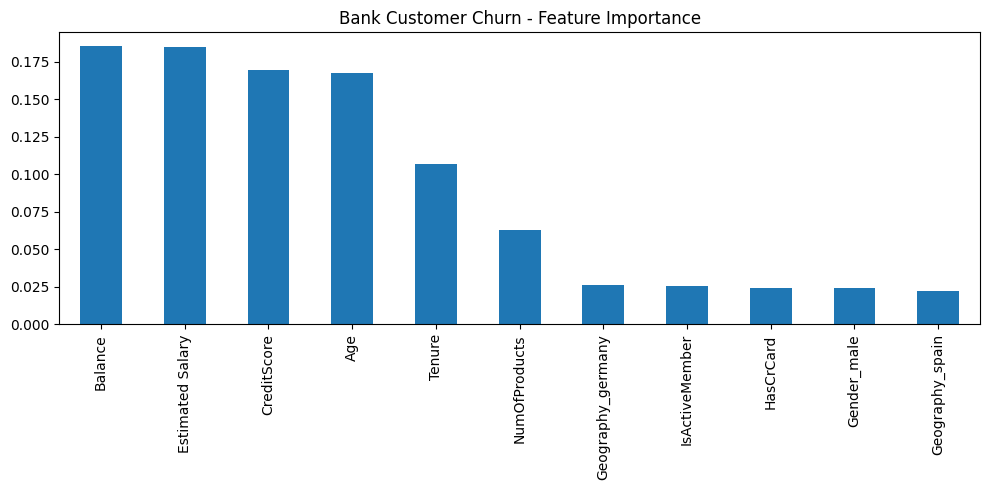

In [33]:
plt.figure(figsize=(10,5))
importance.plot(kind='bar')

plt.title('Bank Customer Churn - Feature Importance')
plt.tight_layout()

plt.savefig('feature_importance.png')
plt.show()